In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
customer_data = pd.read_csv('Customer_Data.csv')
customer_data

,Income,SpendingScore
0,268,83
1,51,22
2,76,84
3,57,15
4,173,37
...,...,...
75,61,80
76,231,88
77,315,17
78,219,12


In [3]:
# 2 input (Income, SpendingScore), tanpa output / label
X = customer_data.iloc[:, :2].values

In [4]:
X.shape

(80, 2)

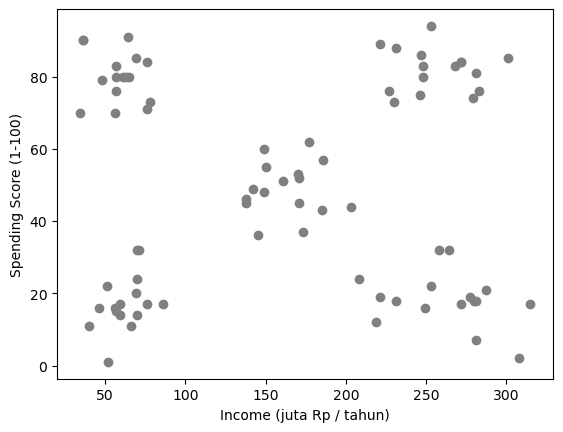

In [5]:
# Visualization
# there is no label, so every point has the same color

plt.scatter(X[:, 0], X[:, 1], c='gray')
plt.xlabel('Income (juta Rp / tahun)')
plt.ylabel('Spending Score (1-100)')
plt.show()

In [6]:
# Feature Scaling (StandardScaler)
# K-Means groups samples by their distance, so every feature must have a similar scale.
# Income is between 30 - 320, but SpendingScore is between 1 - 100, so without scaling the distance is dominated by Income.
# StandardScaler changes every feature to mean = 0 and standard deviation = 1: z = (x - mean) / std
class StandardScaler:
    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, X):
        X = np.array(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        return self

    def transform(self, X):
        X = np.array(X, dtype=float)
        return (X - self.mean_) / self.std_

    def inverse_transform(self, X):
        # back to the original units (used to show the centroids)
        X = np.array(X, dtype=float)
        return X * self.std_ + self.mean_

In [7]:
scaler = StandardScaler().fit(X)
X_scaled = scaler.transform(X)

print('mean: ', scaler.mean_)
print('std : ', scaler.std_)
X_scaled[:5].round(3)

mean:  [160.625   49.3625]
std :  [91.52368204 29.0762978 ]


array([[ 1.173,  1.157],
       [-1.198, -0.941],
       [-0.925,  1.191],
       [-1.132, -1.182],
       [ 0.135, -0.425]])

In [8]:
# K-Means Implementation
# the KMeans class groups the data into n_clusters groups without using any label.
# fit starts with K random samples as centroids, then repeats two steps until the centroids stop moving:
#   1. assignment step: every sample joins the cluster of its closest centroid
#   2. update step    : every centroid moves to the mean of the samples in its cluster
# centroid_history_, labels_history_ and inertia_history_ store every iteration (used for the animation).
class KMeans:
    def __init__(self, n_clusters=3, max_iter=100, random_state=None):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state
        self.centroids_ = None
        self.labels_ = None
        self.inertia_ = None
        self.centroid_history_ = []
        self.labels_history_ = []
        self.inertia_history_ = []

    def _distances(self, X, centroids):
        # Euclidean distance from every sample to every centroid -> shape (n_samples, n_clusters)
        return np.array([np.sqrt(np.sum((X - c) ** 2, axis=1)) for c in centroids]).T

    def _inertia(self, X, labels, centroids):
        # sum of squared distances from every sample to its own centroid
        return np.sum((X - centroids[labels]) ** 2)

    # Training
    def fit(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        # initialization: pick K random samples as the first centroids
        rng = np.random.RandomState(self.random_state)
        centroids = X[rng.choice(len(X), self.n_clusters, replace=False)]

        self.centroid_history_ = [centroids.copy()]
        self.labels_history_ = []
        self.inertia_history_ = []

        for _ in range(self.max_iter):
            # 1. assignment step
            labels = np.argmin(self._distances(X, centroids), axis=1)

            # 2. update step (an empty cluster keeps its old centroid)
            new_centroids = np.array([X[labels == k].mean(axis=0) if np.any(labels == k) else centroids[k]
                                      for k in range(self.n_clusters)])

            self.labels_history_.append(labels)
            self.inertia_history_.append(self._inertia(X, labels, centroids))
            self.centroid_history_.append(new_centroids.copy())

            # stop when the centroids do not move anymore (converged)
            if np.allclose(new_centroids, centroids):
                break
            centroids = new_centroids

        self.centroids_ = centroids
        self.labels_ = labels
        self.inertia_ = self._inertia(X, labels, centroids)
        return self

    # Testing: a new sample joins the cluster of its closest centroid
    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return np.argmin(self._distances(X, self.centroids_), axis=1)

In [9]:
#Fitting Model
kmeans = KMeans(n_clusters=5, random_state=1)
kmeans.fit(X_scaled)

In [10]:
print('number of iterations: ', len(kmeans.labels_history_))
print('inertia: ', kmeans.inertia_)
print('centroids (original units):')
print(scaler.inverse_transform(kmeans.centroids_).round(1))

number of iterations:  9
inertia:  8.552601788528008
centroids (original units):
[[ 58.3  80.1]
 [256.7  81.9]
 [163.   48.9]
 [262.8  18.4]
 [ 62.4  17.4]]


In [11]:
# cluster of every customer
kmeans.labels_

array([1, 4, 0, 4, 2, 4, 3, 4, 2, 1, 4, 0, 0, 3, 2, 1, 2, 3, 2, 2, 1, 3,
       2, 4, 1, 0, 2, 1, 2, 2, 0, 0, 0, 3, 3, 4, 0, 4, 0, 4, 2, 0, 4, 1,
       2, 1, 0, 1, 2, 3, 3, 4, 4, 3, 0, 3, 3, 4, 1, 2, 2, 1, 0, 0, 3, 0,
       1, 2, 4, 1, 3, 4, 3, 1, 4, 0, 1, 3, 3, 1])

In [12]:
# # Animation: how the centroids move during training
# # frame 0 = random initial centroids (no cluster yet), then one frame per iteration:
# # the samples are colored by their cluster, the crosses are the centroids, the lines are the path of every centroid.
# from matplotlib.animation import FuncAnimation, PillowWriter
# from IPython.display import HTML

# colors = np.array(['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple'])
# centroid_history = np.array([scaler.inverse_transform(c) for c in kmeans.centroid_history_])
# labels_history = kmeans.labels_history_
# inertia_history = kmeans.inertia_history_
# n_frames = len(labels_history) + 1

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=80)

# def update(i):
#     # left: data colored by cluster + centroids and their path
#     ax1.clear()
#     if i == 0:
#         ax1.scatter(X[:, 0], X[:, 1], c='gray', alpha=0.6)
#         title = 'Initialization: random centroids'
#     else:
#         ax1.scatter(X[:, 0], X[:, 1], c=colors[labels_history[i - 1]], alpha=0.6)
#         title = f'Iteration {i}  |  inertia = {inertia_history[i - 1]:.2f}'
#     for k in range(kmeans.n_clusters):
#         ax1.plot(centroid_history[:i + 1, k, 0], centroid_history[:i + 1, k, 1], c='k', lw=1)
#         ax1.scatter(centroid_history[i, k, 0], centroid_history[i, k, 1], c=colors[k], marker='X', s=250, edgecolors='k')
#     ax1.set_xlim(20, 340)
#     ax1.set_ylim(-5, 105)
#     ax1.set_xlabel('Income (juta Rp / tahun)')
#     ax1.set_ylabel('Spending Score (1-100)')
#     ax1.set_title(title)

#     # right: inertia for every iteration, the dot shows the current iteration
#     ax2.clear()
#     iterations = np.arange(1, len(inertia_history) + 1)
#     ax2.plot(iterations, inertia_history, 'o-', c='lightgray')
#     if i > 0:
#         ax2.plot(iterations[:i], inertia_history[:i], 'o-', c='g')
#         ax2.plot([i], [inertia_history[i - 1]], 'o', c='r', ms=10)
#     ax2.set_xticks(iterations)
#     ax2.set_xlabel('Iteration')
#     ax2.set_ylabel('Inertia')
#     ax2.set_title('Inertia')

# update(0)
# fig.tight_layout()

# anim = FuncAnimation(fig, update, frames=range(n_frames), interval=1000)
# plt.close(fig)

# plt.rcParams['animation.frame_format'] = 'jpeg'  # smaller notebook file than png frames
# HTML(anim.to_jshtml())

In [13]:
# # Save the animation as a GIF (for slides / sharing)
# anim.save('training_animation.gif', writer=PillowWriter(fps=1))

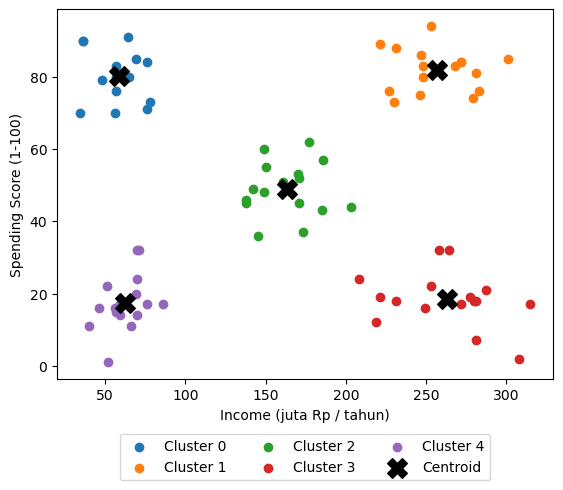

In [14]:
# Visualization
# every color is one cluster, X = centroid

colors = np.array(['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple'])
centroids = scaler.inverse_transform(kmeans.centroids_)

for k in range(kmeans.n_clusters):
    plt.scatter(X[kmeans.labels_ == k, 0], X[kmeans.labels_ == k, 1], c=colors[k], label=f'Cluster {k}')
plt.scatter(centroids[:, 0], centroids[:, 1], c='k', marker='X', s=200, label='Centroid')
plt.xlabel('Income (juta Rp / tahun)')
plt.ylabel('Spending Score (1-100)')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3)
plt.show()

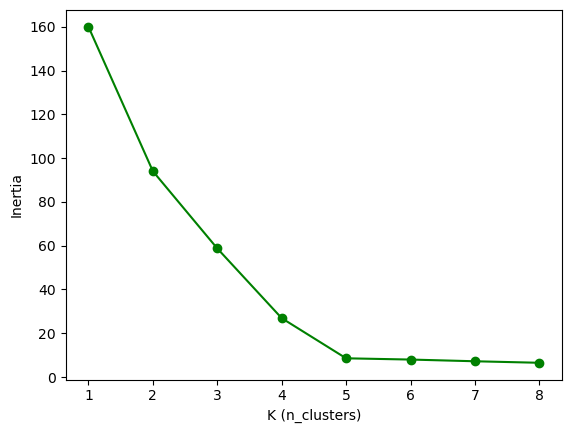

In [15]:
# Elbow Method
# inertia always goes down when K goes up, choose K at the "elbow" where the curve starts to flatten
k_values = range(1, 9)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=1).fit(X_scaled)
    inertias.append(model.inertia_)

plt.plot(k_values, inertias, 'o-', c='g')
plt.xlabel('K (n_clusters)')
plt.ylabel('Inertia')
plt.show()

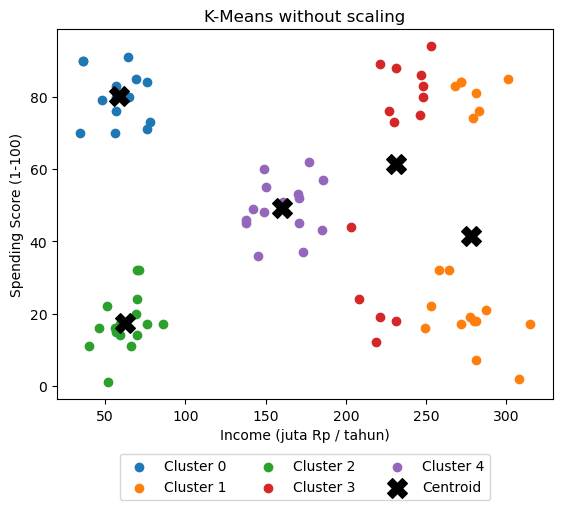

In [16]:
# without scaling Income dominates the distance, so the clusters are only split by Income
kmeans_unscaled = KMeans(n_clusters=5, random_state=1).fit(X)

for k in range(5):
    plt.scatter(X[kmeans_unscaled.labels_ == k, 0], X[kmeans_unscaled.labels_ == k, 1], c=colors[k], label=f'Cluster {k}')
plt.scatter(kmeans_unscaled.centroids_[:, 0], kmeans_unscaled.centroids_[:, 1], c='k', marker='X', s=200, label='Centroid')
plt.title('K-Means without scaling')
plt.xlabel('Income (juta Rp / tahun)')
plt.ylabel('Spending Score (1-100)')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3)
plt.show()

In [17]:
# Cluster profiling: average Income & SpendingScore of every cluster
customer_data['Cluster'] = kmeans.labels_
profile = customer_data.groupby('Cluster').agg(Income=('Income', 'mean'),
                                               SpendingScore=('SpendingScore', 'mean'),
                                               n_customers=('Income', 'size')).round(1)

# give every cluster a name by comparing it with the overall average
def describe(row):
    income = 'tinggi' if row['Income'] > customer_data['Income'].mean() * 1.2 else \
             'rendah' if row['Income'] < customer_data['Income'].mean() * 0.8 else 'sedang'
    spending = 'tinggi' if row['SpendingScore'] > customer_data['SpendingScore'].mean() * 1.2 else \
               'rendah' if row['SpendingScore'] < customer_data['SpendingScore'].mean() * 0.8 else 'sedang'
    return f'Income {income}, Spending {spending}'

profile['description'] = profile.apply(describe, axis=1)
profile

,Income,SpendingScore,n_customers,description
Cluster,,,,
0,58.3,80.1,16,"Income rendah, Spending tinggi"
1,256.7,81.9,16,"Income tinggi, Spending tinggi"
2,163.0,48.9,16,"Income sedang, Spending sedang"
3,262.8,18.4,16,"Income tinggi, Spending rendah"
4,62.4,17.4,16,"Income rendah, Spending rendah"


In [18]:
# [Income, SpendingScore] -> new data must be scaled with the same scaler
prediksi = kmeans.predict(scaler.transform([[70, 85],[280, 15]]))
prediksi

array([0, 3])

In [19]:
profile.loc[prediksi, 'description']

Cluster
0    Income rendah, Spending tinggi
3    Income tinggi, Spending rendah
Name: description, dtype: object

# Algoritma K-Means Clustering

K-Means adalah algoritma **unsupervised learning** untuk **clustering**, yaitu mengelompokkan data yang **tidak memiliki label** menjadi $K$ kelompok (cluster). Data yang mirip (jaraknya dekat) masuk ke cluster yang sama.

Pada notebook ini kita memakai data **pelanggan mall** (`Customer_Data.csv`):
- `Income` = penghasilan pelanggan (juta Rp / tahun)
- `SpendingScore` = skor belanja pelanggan (1 – 100), semakin besar semakin sering berbelanja

Tidak ada kolom target / label. Model sendiri yang harus menemukan kelompok-kelompok pelanggan.

## Supervised vs Unsupervised

| | Supervised (Linear / Logistic Regression, Decision Tree) | Unsupervised (K-Means) |
|---|---|---|
| Data | input $X$ **dan** label $y$ | hanya input $X$ |
| Tujuan | memprediksi label | menemukan kelompok / pola |
| Train-test split | ya | tidak perlu |
| Evaluasi | accuracy, confusion matrix, MSE | inertia, elbow method |

## K-Means vs KNN

Nama keduanya mirip dan sama-sama memakai huruf $K$ dan jarak, tapi algoritmanya berbeda:

| | K-Means | KNN (K-Nearest Neighbors) |
|---|---|---|
| Jenis | **unsupervised** (clustering) | **supervised** (classification) |
| Butuh label? | tidak | ya |
| Arti $K$ | jumlah cluster | jumlah tetangga yang ikut voting |
| Hasil | label cluster untuk setiap data | prediksi kelas untuk data baru |

## Istilah penting

- **Cluster** = kelompok data yang mirip
- **Centroid** = titik pusat sebuah cluster (rata-rata semua data di cluster tersebut)
- **Inertia** = total jarak kuadrat setiap data ke centroid cluster-nya, semakin kecil semakin rapat cluster-nya
- **Konvergen** = kondisi ketika centroid sudah tidak bergerak lagi

## Rumus utama

### Jarak Euclidean

Untuk menentukan centroid terdekat, K-Means menghitung jarak antara data $x$ dan centroid $c_k$:

$$
d(x, c_k) = \sqrt{(x_1 - c_{k1})^2 + (x_2 - c_{k2})^2}
$$

### Centroid

Centroid adalah rata-rata semua data di dalam cluster $C_k$:

$$
c_k = \frac{1}{|C_k|} \sum_{x \in C_k} x
$$

### Inertia (Within-Cluster Sum of Squares)

$$
Inertia = \sum_{k=1}^{K} \sum_{x \in C_k} \lVert x - c_k \rVert^2
$$

Tujuan K-Means adalah mencari posisi centroid yang membuat inertia **sekecil mungkin**.

## Feature Scaling

Rentang `Income` (30 – 320) jauh lebih lebar daripada rentang `SpendingScore` (1 – 100). Tanpa scaling, jarak hampir seluruhnya ditentukan oleh `Income`, sehingga cluster hanya terbagi berdasarkan penghasilan.

Karena itu data di-standardisasi terlebih dahulu:

$$
z = \frac{x - \mu}{\sigma}
$$

Pada plot *K-Means without scaling* di atas terlihat akibatnya: pelanggan dengan income tinggi dibagi berdasarkan income saja, bukan berdasarkan spending score.

Setelah clustering, centroid dikembalikan ke satuan asli dengan `inverse_transform` ($x = z \cdot \sigma + \mu$) supaya mudah dibaca.

## Langkah-langkah algoritma

### 1. Inisialisasi centroid
Pilih $K$ data secara acak sebagai centroid awal:

```python
rng = np.random.RandomState(self.random_state)
centroids = X[rng.choice(len(X), self.n_clusters, replace=False)]
```

### 2. Assignment step
Hitung jarak setiap data ke setiap centroid, lalu masukkan data ke cluster dengan centroid **terdekat**:

```python
labels = np.argmin(self._distances(X, centroids), axis=1)
```

### 3. Update step
Pindahkan setiap centroid ke **rata-rata** data di cluster-nya:

```python
new_centroids = np.array([X[labels == k].mean(axis=0) ... for k in range(self.n_clusters)])
```

Jika sebuah cluster kosong (tidak ada data), centroid-nya tetap di posisi lama.

### 4. Ulangi sampai konvergen
Langkah 2 dan 3 diulang sampai centroid tidak bergerak lagi (atau sampai `max_iter`):

```python
if np.allclose(new_centroids, centroids):
    break
```

Setiap iterasi pasti membuat inertia turun atau tetap, sehingga algoritma selalu berhenti.

Posisi centroid, label, dan inertia di setiap iterasi disimpan di `centroid_history_`, `labels_history_`, dan `inertia_history_`. Data ini dipakai untuk membuat **animasi** pergerakan centroid.

### 5. Simpan hasil model

```python
self.centroids_ = centroids
self.labels_ = labels
self.inertia_ = self._inertia(X, labels, centroids)
```

### 6. Prediksi data baru
Data baru masuk ke cluster dengan centroid terdekat:

```python
return np.argmin(self._distances(X, self.centroids_), axis=1)
```

## Memilih jumlah cluster K: Elbow Method

K-Means tidak tahu berapa jumlah cluster yang tepat, jadi $K$ harus kita tentukan. Caranya:

1. Jalankan K-Means untuk $K = 1, 2, 3, \dots$
2. Catat inertia untuk setiap $K$
3. Gambar grafik $K$ vs inertia

Inertia selalu turun jika $K$ bertambah (paling ekstrem: setiap data menjadi cluster sendiri, inertia = 0). Kita pilih $K$ di titik **siku (elbow)**, yaitu titik di mana penambahan cluster tidak lagi menurunkan inertia secara signifikan. Pada data ini, siku berada di **K = 5**.

## Hasil awal yang acak

Centroid awal dipilih secara acak, sehingga hasil K-Means bisa berbeda-beda dan kadang terjebak di solusi yang kurang baik (*local minimum*). Solusinya adalah menjalankan K-Means beberapa kali dengan inisialisasi berbeda, lalu memilih hasil dengan inertia terkecil. Inilah yang dilakukan parameter `n_init` pada `KMeans` di scikit-learn.

## Interpretasi Cluster

Setelah cluster ditemukan, kita melihat rata-rata setiap cluster (**cluster profiling**) untuk memberi arti, misalnya:
- Income tinggi, Spending tinggi → pelanggan premium, target produk eksklusif
- Income tinggi, Spending rendah → pelanggan hemat, perlu promo yang menarik
- Income rendah, Spending tinggi → pelanggan aktif, cocok untuk program loyalitas
- Income rendah, Spending rendah → pelanggan sensitif harga, cocok untuk diskon
- Income dan Spending sedang → pelanggan rata-rata

## Intuisi sederhana

Bayangkan ada 5 tenda di sebuah lapangan dan banyak orang yang berdiri di sekitarnya:

1. Setiap orang berjalan ke tenda yang paling dekat
2. Setiap tenda dipindahkan ke tengah-tengah orang yang mendatanginya
3. Ulangi sampai tenda tidak berpindah lagi

Pada akhirnya setiap tenda berada di tengah satu kelompok orang. Itulah cara kerja K-Means.

## Kesimpulan

Algoritma K-Means bekerja dengan cara:

1. Menyiapkan data input tanpa label
2. Melakukan feature scaling
3. Memilih $K$ centroid awal secara acak
4. Memasukkan setiap data ke cluster dengan centroid terdekat
5. Memindahkan centroid ke rata-rata data di cluster-nya
6. Mengulangi langkah 4–5 sampai centroid tidak bergerak (konvergen)
7. Memilih $K$ terbaik dengan elbow method, lalu menginterpretasikan setiap cluster

Itulah dasar dari algoritma K-Means untuk clustering.